<a href="https://colab.research.google.com/github/3b232076/2026_DL_hws/blob/main/hw4_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HW4-3 四資四乙 3B232076-陳韻如

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.utils import to_categorical
from ipywidgets import interact_manual

## 顯示中文

In [ ]:
# 下載思源黑體字型（支援中文）
!wget -qO /usr/share/fonts/truetype/NotoSansCJKtc-Regular.otf https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf

# 重新載入字型
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/NotoSansCJKtc-Regular.otf')
plt.rcParams['font.family'] = 'Noto Sans CJK TC'

## 一、資料預處理

In [ ]:
# 下載 CIFAR-10 數據集
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

 21807104/170498071 ━━━━━━━━━━━━━━━━━━━━ 26:05 11us/step

In [ ]:
# 顯示資料形狀
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
x_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


## 資料常模化(normalization)

In [ ]:
x_train = x_train / 255
x_test = x_test / 255

## One-hot encoding

In [ ]:
y_train_oh = to_categorical(y_train, 10)
y_test_oh = to_categorical(y_test, 10)

## 顯示三張訓練圖片與真實標籤

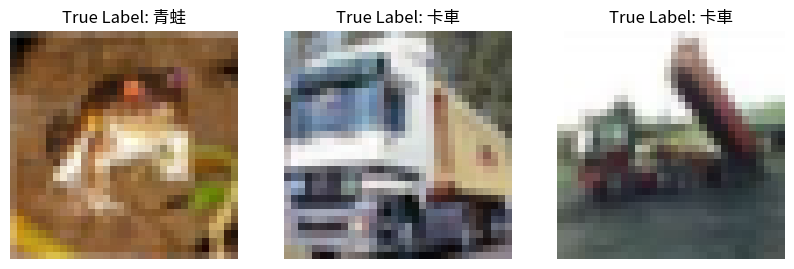

In [ ]:
class_name = ['飛機', '汽車', '鳥', '貓', '鹿', '狗', '青蛙', '馬', '船', '卡車']

plt.figure(figsize=(10,4))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_train[i])
    plt.title(f"True Label: {class_name[y_train[i].item()]}")
    plt.axis('off')
plt.show()

## 二、建立神經網路模型

In [ ]:
model = Sequential()

### 第一層：卷積層 (32 個 Filter，大小為 3x3)
* 圖片尺寸為 32x32
* 彩色圖片 3 通道（RGB）
* (32, 32, 32)
* 卷積層參數 = (Filter高 × Filter寬 × 前層輸入通道數 + 偏值) × 本層通道數

In [ ]:
model.add(Conv2D(32, (3,3), padding='same',
        input_shape=(32,32,3),
        activation='relu'))  # (3x3x3+1)x32 = 896

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 第二層：Dropout 0.3

In [ ]:
model.add(Dropout(0.3))

### 第三層：卷積層 (32 個 Filter，大小為 3x3)
* 圖片尺寸為 32x32
* (32, 32, 32)
* 前一層輸出 32 個通道
* 本層 32 通道

In [ ]:
model.add(Conv2D(32, (3,3), padding='same',
        activation='relu',))  # (3x3x32+1)x32 = 9248

### 第四層：池化層
* (32, 32, 32) → (16, 16, 32)
* 保留前一層 32 個通道

In [ ]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第五層：卷積層 (64 個 Filter，大小為 3x3)
* 圖片尺寸為 16x16
* (16, 16, 64)
* 前一層輸出 32 個通道
* 本層 64 通道

In [ ]:
model.add(Conv2D(64, (3,3), padding='same',
        activation='relu',))  # (3x3x32+1)x64 = 18496

### 第六層：Dropout 0.3

In [ ]:
model.add(Dropout(0.3))

### 第七層：卷積層 (64 個 Filter，大小為 3x3)
* 圖片尺寸為 16x16
* (16, 16, 64)
* 前一層輸出 64 個通道
* 本層 64 通道

In [ ]:
model.add(Conv2D(64, (3,3), padding='same',
        activation='relu',))  # (3x3x64+1)x64 = 36928

### 第八層：池化層
* (16, 16, 64) → (8, 8, 64)
* 保留前一層 64 個通道

In [ ]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第九層：卷積層 (128 個 Filter，大小為 3x3)
* 圖片尺寸為 8x8
* (8, 8, 128)
* 前一層輸出 64 個通道
* 本層 128 通道

In [ ]:
model.add(Conv2D(128, (3,3), padding='same',
        activation='relu',))  # (3x3x64+1)x128 = 73856

### 第十層：Dropout 0.3

In [ ]:
model.add(Dropout(0.3))

### 第十一層：卷積層 (128 個 Filter，大小為 3x3)
* 圖片尺寸為 8x8
* (8, 8, 128)
* 前一層輸出 128 個通道
* 本層 128 通道

In [ ]:
model.add(Conv2D(128, (3,3), padding='same',
        activation='relu',))  # (3x3x128+1)x128 = 147584

### 第十二層：池化層
* (8, 8, 128) → (4, 4, 128)
* 保留前一層 128 個通道

In [ ]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第十三層：拉平層
* (4, 4, 128) → 2048

In [ ]:
model.add(Flatten())

### 第十四層：Dropout 0.3

In [ ]:
model.add(Dropout(0.3))

### 第十五層：全連接層 (2500 個神經元)
* 2500 個神經元對應 CIFAR-10 的 10 類別
* 每個神經元連接前一層的 2048 個輸入，共有 5120000 個權重 + 2500 個偏值 = 5122500 個參數。

In [ ]:
model.add(Dense(2500, activation='relu')) # 2048x2500+2500 = 5122500

### 第十六層：Dropout 0.3

In [ ]:
model.add(Dropout(0.3))

### 第十七層：全連接層 (1500 個神經元)
* 前一層的 2500 個通道 x 本層 1500 個通道 + 1500 個偏值 = 3751500 個參數。

In [ ]:
model.add(Dense(1500, activation='relu')) # 2500x1500+1500 = 3751500

### 第十八層：Dropout 0.3

In [ ]:
model.add(Dropout(0.3))

### 第十九層：全連接層 (10 個神經元)

In [ ]:
model.add(Dense(10, activation='softmax')) # 1500x10+10 = 15010

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

### 批次訓練 Input Shape 與各層 Output Shape

批次大小（batch_size）設定為 128，每次輸入 128 張 32×32 的 RGB 圖片。

Input Shape：(128, 32, 32, 3)

各層 Output Shape：
1. Conv2D：(128, 32, 32, 32)
2. Dropout：(128, 32, 32, 32)
3. Conv2D：(128, 32, 32, 32)
4. MaxPooling2D：(128, 16, 16, 32)
5. Conv2D：(128, 16, 16, 64)
6. Dropout：(128, 16, 16, 64)
7. Conv2D：(128, 16, 16, 64)
8. MaxPooling2D：(128, 8, 8, 64)
9. Conv2D：(128, 8, 8, 128)
10. Dropout：(128, 8, 8, 128)
11. Conv2D：(128, 8, 8, 128)
12. MaxPooling2D：(128, 4, 4, 128)
13. Flatten：(128, 2048)
14. Dropout：(128, 2048)
15. Dense：(128, 2500)
16. Dropout：(128, 2500)
17. Dense：(128, 1500)
18. Dropout：(128, 1500)
19. Dense：(128, 10)

以上為完整批次的形狀，最後一個批次可能不足128 筆。

## 三、訓練神經網路模型

In [ ]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy'])

In [ ]:
train_history = model.fit(
    x_train, y_train_oh,
    validation_split=0.2,
    batch_size=128,
    epochs=50,
    verbose=2)

Epoch 1/50
313/313 - 430s - 1s/step - accuracy: 0.3221 - loss: 1.8080 - val_accuracy: 0.4028 - val_loss: 1.6839
Epoch 2/50
313/313 - 415s - 1s/step - accuracy: 0.4850 - loss: 1.4068 - val_accuracy: 0.5477 - val_loss: 1.2695
Epoch 3/50
313/313 - 456s - 1s/step - accuracy: 0.5617 - loss: 1.2128 - val_accuracy: 0.5803 - val_loss: 1.1519
Epoch 4/50
313/313 - 407s - 1s/step - accuracy: 0.6146 - loss: 1.0831 - val_accuracy: 0.6349 - val_loss: 1.0352
Epoch 5/50
313/313 - 428s - 1s/step - accuracy: 0.6454 - loss: 1.0002 - val_accuracy: 0.6723 - val_loss: 0.9279
Epoch 6/50
313/313 - 408s - 1s/step - accuracy: 0.6696 - loss: 0.9243 - val_accuracy: 0.6802 - val_loss: 0.9111
Epoch 7/50
313/313 - 441s - 1s/step - accuracy: 0.6988 - loss: 0.8547 - val_accuracy: 0.6985 - val_loss: 0.8522
Epoch 8/50
313/313 - 465s - 1s/step - accuracy: 0.7136 - loss: 0.8082 - val_accuracy: 0.7129 - val_loss: 0.8251
Epoch 9/50
313/313 - 440s - 1s/step - accuracy: 0.7307 - loss: 0.7570 - val_accuracy: 0.7151 - val_loss:

## 四、顯示 loss & accuracy 折線圖

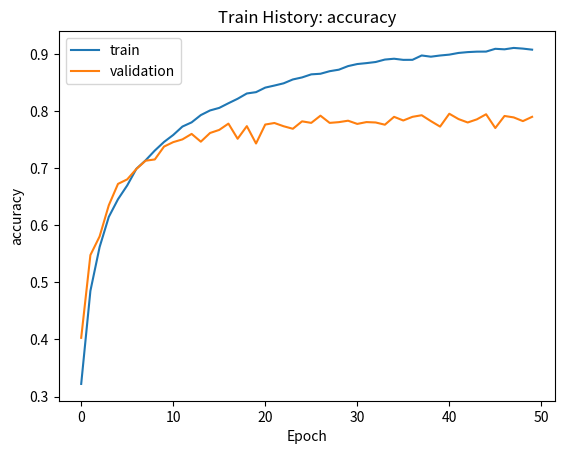

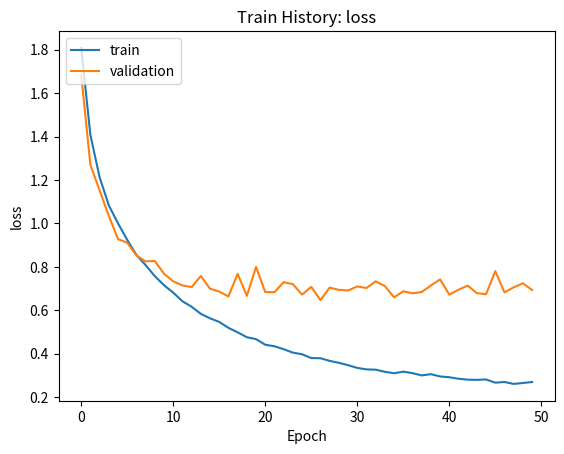

In [ ]:
def show_train_history(train_history, train, validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title(f'Train History: {train}')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train', 'validation'], loc='upper left')
  plt.show()

show_train_history(train_history, 'accuracy', 'val_accuracy')
show_train_history(train_history, 'loss', 'val_loss')

### Overfitting 分析

從訓練結果可以觀察到，隨著 Epoch 增加，訓練 Accuracy 整體呈現上升趨勢，Loss 則逐漸下降。

第 50 個 Epoch 的訓練 Accuracy 為 90.73%，驗證 Accuracy 為 78.97%，兩者相差 11.76 個百分點。

此外，訓練 Loss 為 0.2697，驗證 Loss 為 0.6933，顯示模型仍有過度擬合（Overfitting）的現象。

與 hw4-2 相比，hw4-3 的訓練與驗證準確率差距較小，且測試準確率較高，表示模型的泛化表現有所提升。

## 五、評估模型準確率

In [ ]:
scores = model.evaluate(x_test, y_test_oh)
print(f"accuracy: {scores[1]*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.7802 - loss: 0.7295
accuracy: 78.02%


## 六、預測

In [ ]:
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 89ms/step


In [ ]:
predictions.shape

(10000, 10)

In [ ]:
predictions

array([[3.1767387e-04, 2.6373677e-05, 2.7257553e-04, ..., 1.3432711e-04,
        9.9465228e-04, 1.6736102e-04],
       [6.0207275e-04, 8.4993651e-04, 5.0465760e-09, ..., 4.7142281e-09,
        9.9849743e-01, 4.9491227e-05],
       [3.0262085e-02, 8.2713375e-03, 1.0862626e-03, ..., 9.5452750e-03,
        9.2980438e-01, 1.5603491e-02],
       ...,
       [2.1417097e-10, 1.5185388e-12, 1.6435937e-05, ..., 1.0829287e-06,
        9.2913882e-10, 1.2404234e-09],
       [2.2650050e-02, 9.5162928e-01, 1.0993417e-03, ..., 3.2532250e-03,
        1.2536648e-06, 4.9036038e-03],
       [7.9013280e-19, 6.3998234e-31, 1.2683359e-16, ..., 9.9999720e-01,
        2.8582246e-26, 2.0703813e-26]], shape=(10000, 10), dtype=float32)

In [ ]:
predicted_classes = np.argmax(predictions, axis=1)

## 七、顯示圖片與標籤名稱

In [ ]:
import matplotlib.pyplot as plt

def plot_images_labels_prediction(images, true_labels, pred_labels, label_names, idx, num):
  plt.figure(figsize=(6, 7))
  if num > 25: num = 25
  for i in range(num):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[idx + i])

    true_idx = np.squeeze(true_labels[idx + i])
    pred_idx = np.squeeze(pred_labels[idx + i])

    true_name = label_names[true_idx]
    pred_name = label_names[pred_idx]

    plt.title(f'True: {true_name}\nPred: {pred_name}', fontsize=10)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

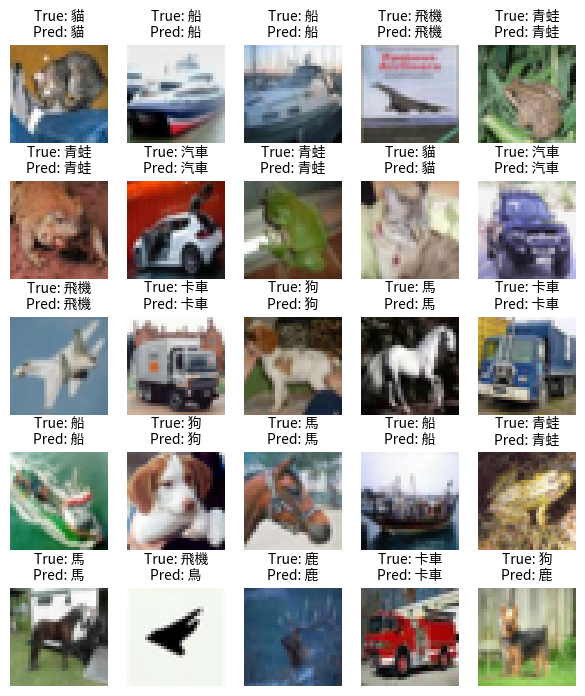

In [ ]:
plot_images_labels_prediction(x_test, y_test, predicted_classes, class_name, idx=0, num=25)

## 八、混淆矩陣 (Confusion Matrix)

In [ ]:
import pandas as pd

pd.crosstab(np.squeeze(y_test), predicted_classes, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,811,10,54,17,17,8,11,12,45,15
1,8,899,5,6,3,5,12,3,16,43
2,49,2,713,41,86,39,50,13,6,1
3,20,0,77,557,66,178,63,26,5,8
4,11,0,70,38,778,34,27,40,2,0
5,10,2,37,134,51,700,28,32,4,2
6,5,2,41,39,35,17,854,3,4,0
7,11,0,34,36,64,55,6,790,2,2
8,40,20,16,15,7,9,8,3,864,18


## 九、儲存完整模型

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/

/content/drive/MyDrive/Colab Notebooks


In [ ]:
model.save('cnn_cifar10_model_4-3.keras')

## 十、interact_manual

In [ ]:
def test(測試編號):
  plt.imshow(x_test[測試編號], cmap='Greys')
  print('神經網路判斷為：', class_name[predicted_classes[測試編號]])
  print('正確答案為：', class_name[np.squeeze(y_test[測試編號])])

interact_manual(test, 測試編號=(0, len(x_test)-1))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

<function __main__.test(測試編號)>

### 比較結果分析

hw4-2 使用 11 層 CNN 架構，而 hw4-3 增加至 19 層，包含更多卷積層及全連接層，並將 Dropout 調整為 0.3。

從測試結果可以發現，hw4-2 的準確率為 72.87%，hw4-3 則提升至 78.02%，增加了 5.15 個百分點。

雖然 hw4-3 的模型參數較多，且訓練次數增加至 50 Epochs，但其測試準確率較高，最後一個 Epoch 的驗證 Loss 也較低。

兩個模型皆有 Overfitting 現象，但 hw4-3 的訓練與驗證準確率差距較小，顯示泛化表現相對較佳。

整體而言，hw4-3 在測試準確率方面，優於 hw4-2，但模型複雜度及訓練成本也較高。